# Getting Started with tidycarbon

Measuring the energy and emissions of R programs

Sean Hamilton-Palicki [ORCID profile for Sean
Hamilton-Palicki](https://orcid.org/https://orcid.org/0000-0002-7797-9646)
(Technical University of Munich)

## Learning Objectives

By the end of this tutorial, you will be able to

1.  Set up TidyCarbon and initialize local and remote trackers,
2.  Measure the time, energy, emissions and water use of R code, from
    whole scripts to single pipeline steps,
3.  Compare the energy use of alternative methods with carbon_bench(),
    and
4.  Estimate the energy use of LLM API calls.

## Target audience

This tutorial is aimed at social scientists who use R for computational
analyses and want to measure their environmental impact. Prior knowledge
of R and the tidyverse package is required. Basic familiarity with text
analysis is helpful.

## Setting up the computational environment

TidyCarbon requires reticulate, which creates a Python environment that
loads the CodeCarbon and EcoLogits dependencies.

But first we do some housecleaning to make Colab run much faster. We will download the pre-compiled binaries for Cpp based R packages.

In [1]:
options(repos = c(
  CRAN = "https://packagemanager.posit.co/cran/latest"
))

In [2]:
system("cat /etc/os-release")
R.version.string
R.version$platform

[1] "R version 4.6.1 (2026-06-24)"

[1] "x86_64-pc-linux-gnu"

In [3]:
options(repos = c(
  CRAN = "https://packagemanager.posit.co/cran/latest/bin/linux/noble-x86_64/4.6"
))

Uncomment to install packages

In [4]:
# install.packages(c("tidytext", "janeaustenr", "topicmodels", "quanteda", "LSX", "tidyverse", "remotes", "tidytext"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘NLP’, ‘BH’, ‘ISOcodes’, ‘nsyllable’, ‘RcppArmadillo’, ‘RcppEigen’, ‘plyr’, ‘tokenizers’, ‘modeltools’, ‘slam’, ‘tm’, ‘fastmatch’, ‘SnowballC’, ‘stopwords’, ‘quanteda.textstats’, ‘RSpectra’, ‘proxyC’, ‘ggrepel’, ‘reshape2’, ‘locfit’




In [5]:
# remotes::install_github("seankellyhp/Tidycarbon")
# remotes::install_github("quanteda/quanteda.sentiment")

png        (NA -> 0.1-9 ) [CRAN]
here       (NA -> 1.0.2 ) [CRAN]
RcppTOML   (NA -> 0.2.3 ) [CRAN]
reticulate (NA -> 1.47.0) [CRAN]


Installing 4 packages: png, here, RcppTOML, reticulate

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



── R CMD build ─────────────────────────────────────────────────────────────────
* checking for file ‘/tmp/RtmpbFtJ4d/remotes116b583f67e8/seankellyhp-Tidycarbon-8c98c3d/DESCRIPTION’ ... OK
* preparing ‘tidycarbon’:
* checking DESCRIPTION meta-information ... OK
* checking for LF line-endings in source and make files and shell scripts
* checking for empty or unneeded directories
* building ‘tidycarbon_0.1.0.tar.gz’



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)





── R CMD build ─────────────────────────────────────────────────────────────────
* checking for file ‘/tmp/RtmpbFtJ4d/remotes116b583d2f4f/quanteda-quanteda.sentiment-0f2a11a/DESCRIPTION’ ... OK
* preparing ‘quanteda.sentiment’:
* checking DESCRIPTION meta-information ... OK
* checking for LF line-endings in source and make files and shell scripts
* checking for empty or unneeded directories
* building ‘quanteda.sentiment_0.4.tar.gz’



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



You may get errors with the topicmodels package unless you run the following to get the libgsl dependency.

In [ ]:
# system("sudo apt-get update && sudo apt-get install -y libgsl-dev")

In [6]:
set.seed(721831)

# Quieten CodeCarbon before the first tracker is created, or knitting can
# hang at the first tracked chunk.
Sys.setenv(CODECARBON_LOG_LEVEL = "error")

TidyCarbon relies on tidyverse packages.

In [7]:
library("tidycarbon")

## Duration

Around 15 minutes

## Use case(s)

- Track and report time, energy, carbon emissions, and water usage for
  computational analysis tasks.
- Track at macro and micro levels of a program: track a complete
  analysis, or insert TidyCarbon into a tidy pipeline to measure it step
  by step.
- Compare speed and energy use for alternative methods of analysis (e.g.
  different methods of sentiment analysis), providing data for reducing
  the computational effort and emissions of analyses.
- Estimate the energy use and emissions of LLM-based analyses on remote
  servers (OpenAI, Anthropic, Mistral) in real time or from chat
  transcripts.

# Tidy Carbon

## Description

TidyCarbon (Hamilton-Palicki & Bravo, 2026) is an open source R package
for measuring and comparing the resource use of R programs. This is
relevant because of the increased reliance of social science research on
computationally complex machine learning and AI methods such as large
language models (<span class="nocase">Balluff et al.</span>, 2026),
which may consume significantly more non-renewable resources than
computationally less advanced methods (Hamilton-Palicki et al., 2026;
Luccioni et al., 2024).

TidyCarbon provides a tidy interface over the Python libraries
[CodeCarbon](https://codecarbon.io) (<span class="nocase">Courty et
al.</span>, 2026), for measuring the energy of local programs, and
[EcoLogits](https://ecologits.ai) (Rincé & Banse, 2025), for estimating
the energy use of API calls to LLM providers. Based on measuring time,
energy, location, and in, the case of API calls, the length of LLM
responses, TidyCarbon provides estimates for equivalent carbon
emissions, and water use needed to run the program. TidyCarbon does not
implement its own algorithms. Instead, it operates as a thin “shim” for
integrating energy and emissions estimates into R analysis workflows.

## Important Functions

TidyCarbon provides functions to track time and energy, and to estimate
emissions, in a limited number of situations. To compare full R
programs, the `tracker_*` functions wrap existing R code you have
already written. For more fine-grained analyses and comparisons, the
`carbon_*` functions operate at the level of pipelines and individual R
functions.

### Function List

| Function | Purpose |
|------------------------------------|------------------------------------|
| `carbon_init()` | Initialize a local tracker. May request access to local RAPL files to measure energy use directly, or estimates it from your machine’s specs. See CodeCarbon for the methodology. |
| `carbon_init_remote()` | Initialize a remote tracker. Estimates emissions for requests made to LLM providers. See EcoLogits for the methodology. |
| `tracker_start()` | Begin tracking energy. Place before R pipelines. |
| `tracker_stop()` | End tracking energy. Place after R pipelines. |
| `carbon_track()` | Measure the energy of a single function call. |
| `carbon_step()` | Insert tracking into an R pipe, measuring the consumption of a single pipeline step. |
| `carbon_bench()` | Directly compare the emissions of functions. |
| `carbon_collect()` | View the results of the `carbon_step()` calls in a pipeline. |

## How to Use

### Initialize local tracking

The following examples demonstrate tracking the resources needed for
computation on a local system. Importantly, measurements are made at the
level of the machine. For accurate comparisons, ensure that no other
compute- or memory-intensive programs (e.g. browsers, long-running
analysis tasks) are running.

In [8]:
Sys.setenv(CODECARBON_LOG_LEVEL = "error")

carbon_init(
  project_name     = "Hello_World",
  output_dir       = file.path(tempdir(), "tidycarbon_results"),
  offline          = TRUE,
  country_iso_code = "DEU"
)

This starts CodeCarbon in the background. The first install may take a
few minutes while the Python environment is set up.

The first line quietens CodeCarbon, which otherwise prints a progress
line for every reading. Keep it when you knit a document: with the
progress lines on, knitting can hang at the first tracked chunk.

The project will be called `Hello_World` in the rows of the resulting
tibble. A CSV of results will be saved to
`tidycarbon_results/emissions_r.csv`. Results are always appended to
this file, so it is the source of truth for all tracking done in the
project.

By default CodeCarbon looks up the country the machine is in, with one
request to a geolocation service, to estimate the carbon intensity of
its electricity. `offline = TRUE` with `country_iso_code` skips that
request.

Carbon intensity is the relationship between energy and the estimated
amount of carbon emitted to generate that electricity. It depends on the
sustainability of local power grids and varies greatly, as Figure 1
shows. Countries such as France have a low carbon intensity because they
generate a higher proportion of their electricity from low-carbon
sources (nuclear, solar). In contrast, Germany and the US generate a
higher proportion from fossil fuels (coal, gas).

![Figure 1. Carbon intensity of electricity across Europe. Green is low, yellow to brown is higher, and grey has no data. Source: Electricity Maps.](../figures/electricity-map.png)

### Basic measurements of an R program

We will demonstrate a standard text analysis, using examples from the
[Tidy Text Mining](https://www.tidytextmining.com) book (Silge &
Robinson, 2017).

#### Load packages and data

We load the Austen books dataset and several tidyverse packages.

In [10]:

library(tidycarbon)

# tidyverse packages
library(dplyr)
library(tidyr)
library(stringr)
library(ggplot2)
library(tidytext)
library(janeaustenr)
library(purrr)

# more advanced analyses downstream
library(topicmodels)
library(quanteda)
library(quanteda.sentiment)
library(LSX)

Package version: 4.5.1
Unicode version: 15.1
ICU version: 74.2

Parallel computing: disabled

See https://quanteda.io for tutorials and examples.


Attaching package: ‘quanteda.sentiment’


The following object is masked from ‘package:quanteda’:

    data_dictionary_LSD2015




In [11]:
carbon_init(
  project_name     = "Austen_tutorial",
  output_dir       = file.path(tempdir(), "tidycarbon_results"),
  offline          = TRUE,
  country_iso_code = "DEU"
)

For the first example, we start the tracker before a pipeline that
counts the top words in Austen’s novels, and stop it afterwards. It is
as simple as placing the tracker before and after existing R code.

#### Tracker start and stop

In [12]:
tracker_start() # Start tracker

books <- austen_books() |>
  group_by(book) |>
  mutate(
    linenumber = row_number(),
    chapter = cumsum(str_detect(
      text,
      regex("^chapter [\\divxlc]", ignore_case = TRUE)
    ))
  ) |>
  ungroup()

books |>
  unnest_tokens(word, text) |>
  anti_join(stop_words, by = "word") |>
  count(book, word, sort = TRUE)

books_emit <- tracker_stop(label = "clean and count words") # End tracker

book,word,n
<fct>,<chr>,<int>
Mansfield Park,fanny,816
Emma,emma,786
Sense & Sensibility,elinor,623
Emma,miss,599
Pride & Prejudice,elizabeth,597
Mansfield Park,crawford,493
Sense & Sensibility,marianne,492
Persuasion,anne,447
Mansfield Park,miss,432


#### Output data

Every measurement is returned as a tibble with one row per tracked task
and columns for the measurements and machine information. As a side
effect, results are automatically appended to the CSV file in the
project folder.

The object `books_emit` is now a one-row tibble of the carbon
measurement. It has all of the columns returned by CodeCarbon, most of
which are not needed for downstream analysis. `glimpse()` shows all of
them:

In [13]:
glimpse(books_emit)

Rows: 1
Columns: 38
$ task_id            <chr> "22ec5bfd-e211-4a7a-ae3d-5cdb80b860d8"
$ label              <chr> "clean and count words"
$ timestamp          <chr> "2026-11-10T17:21:30"
$ wall_time_sec      <dbl> 6.278477
$ emissions_total    <dbl> 3.01867e-06
$ duration           <dbl> 2.851641
$ energy_consumed    <dbl> 7.924057e-06
$ cpu_energy         <dbl> 1.239964e-06
$ ram_energy         <dbl> 6.684093e-06
$ gpu_energy         <dbl> 0
$ output_source      <chr> "emissions_r.csv"
$ project_name       <chr> "Austen_tutorial"
$ run_id             <chr> "679a41df-09e1-46d4-b32b-547c8de66652"
$ experiment_id      <chr> "5b0fa12a-3dd7-45bb-9766-cc326314d9f1"
$ emissions_rate     <dbl> 1.058573e-06
$ cpu_power          <dbl> 1.577727
$ gpu_power          <dbl> 0
$ ram_power          <dbl> 10
$ water_consumed     <dbl> 0
$ country_name       <chr> "Germany"
$ country_iso_code   <chr> "DEU"
$ region             <chr> NA
$ cloud_provider     <chr> ""
$ cloud_region       <chr> ""
$ os    

The results include estimates of time, hardware-level energy
consumption, aggregated energy consumption and an estimate of emissions.
`wall_time_sec` is in seconds, `energy_consumed` in kWh and
`emissions_total` in kgCO2eq. For a task this small, the time and energy
needs are very small, so watt-hours and milligrams are easier to read:

In [14]:
emissions <- books_emit |>
  transmute(
    task_id,
    label,
    wall_time_sec,
    cpu_wh   = cpu_energy * 1000,
    gpu_wh   = gpu_energy * 1000,
    ram_wh   = ram_energy * 1000,
    total_wh = energy_consumed * 1000,
    co2e_mg  = emissions_total * 1e6,
    water_consumed
  )

The selected columns:

| Column | Unit | Description |
|------------------------|------------------------|------------------------|
| `task_id` |  | Unique ID of the tracked task. |
| `label` |  | Label given to the tracked task. |
| `wall_time_sec` | seconds | Elapsed time of the task. |
| `cpu_wh` | Wh | Energy used by the CPU. |
| `gpu_wh` | Wh | Energy used by the GPU. |
| `ram_wh` | Wh | Energy used by the RAM. |
| `total_wh` | Wh | Total energy: CPU, GPU and RAM. |
| `co2e_mg` | mgCO2eq | Estimated emissions: energy times the carbon intensity of the grid. |
| `water_consumed` | litres | Estimated water use. It is 0 for a local machine, which has no water use set. |

This level of analysis is useful for reporting and requires the least
effort. Reporting is a very important part of understanding the
environmental impacts of computational methods. However, as this example
shows, emissions tracking is less meaningful for relatively “simple”
computational methods such as basic transformations of data and counting
tasks.

Efficiency becomes more relevant with big data, machine learning and AI.
Computational costs are related to the time and memory needed to
complete a task. Tasks that are more computationally complex consume
more resources.

### Tracking the efficiency of specific tasks

Now we will take the same data and do a more complex analysis. Counting
and joining are cheap. Fitting a model is not. This stage treats each
chapter as a document and asks latent Dirichlet allocation for six
topics, one per novel. We are interested in the computational needs of
fitting a topic model, not the topics themselves.

`LDA()` needs a document-term matrix, so the pipeline is: label the
chapters, tokenize, drop stop words, count words per chapter, cast to a
matrix, fit. To see what each step in this pipeline costs, wrap each one
in `carbon_step()`. Each `carbon_step()` takes an optional label
describing the task.

In [15]:
label_chapters <- function(data) {
  data |>
    filter(chapter > 0) |>
    unite(document, book, chapter)
}

lda <- books |>
  carbon_step(label_chapters(), label = "label chapters") |>
  carbon_step(unnest_tokens(word, text), label = "tokenize chapters") |>
  carbon_step(
    anti_join(stop_words, by = "word"),
    label = "remove stop words"
  ) |>
  carbon_step(count(document, word), label = "count by chapter") |>
  carbon_step(cast_dtm(document, word, n), label = "cast to dtm") |>
  carbon_step(LDA(k = 6, control = list(seed = 1234)), label = "LDA")

lda

A LDA_VEM topic model with 6 topics.

`lda` is the fitted model, exactly as the plain pipeline would return
it. The carbon measurements are now carried along with the model. Use
`carbon_collect()` to see them, one row per step.

In [16]:
lda_steps <- carbon_collect(lda)

lda_steps |>
  transmute(
    label,
    wall_time_sec,
    energy_wh = energy_consumed * 1000,
    share     = energy_consumed / sum(energy_consumed)
  )

label,wall_time_sec,energy_wh,share
<chr>,<dbl>,<dbl>,<dbl>
label chapters,0.04037833,0.0001301522,0.001118664
tokenize chapters,0.53736973,0.0017912616,0.015395976
remove stop words,0.15414357,0.0006064478,0.005212447
count by chapter,3.22257447,0.0153133863,0.131619265
cast to dtm,0.14797831,0.0004883656,0.004197525
LDA,26.80722094,0.0980164723,0.842456123


Preparing the text is a small fraction of the total. Almost all of the
energy goes into fitting the model:

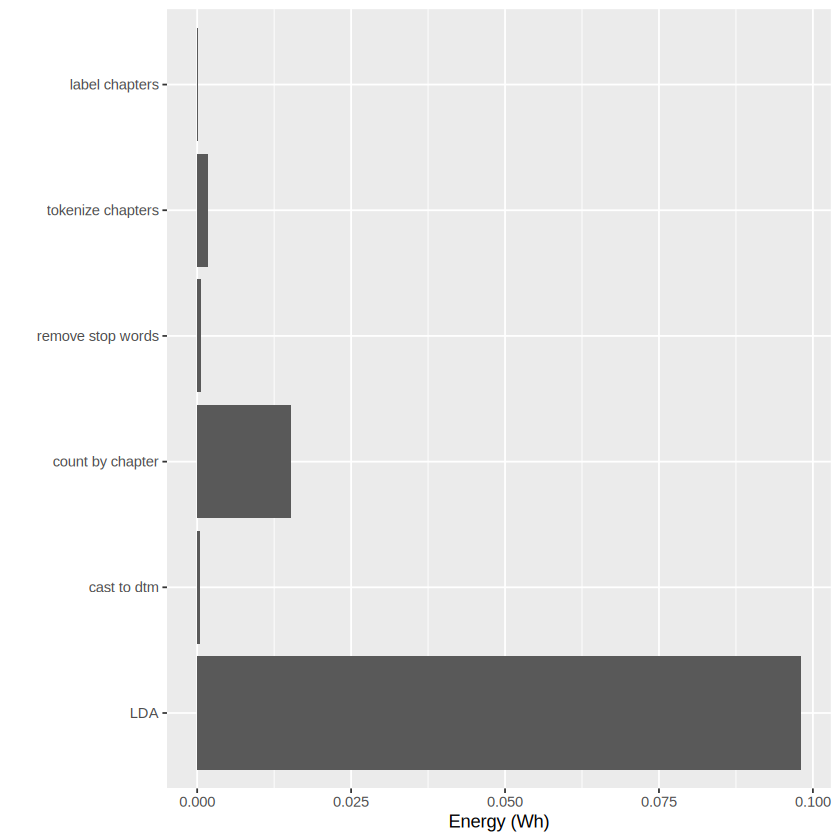

In [17]:
lda_steps |>
  mutate(label = factor(label, levels = rev(label))) |>
  ggplot(aes(energy_consumed * 1000, label)) +
  geom_col() +
  labs(x = "Energy (Wh)", y = NULL)

When an LDA is fit on larger data, with more topics, or with more fits
to find the optimal number of topics (k), these numbers increase. Yet
they are hardly noticeable compared to ever more complex fine-tuning of
transformer models or inference with large language models.

### Comparisons of Simple Sentiment Analysis Approaches

Next we will use three approaches for sentiment analysis, with a focus
on comparing their emissions. We will start with the least complex
approach, tidytext with dictionaries, then move to quanteda sentiments
and latent semantic scaling.

#### Data Preparation

Sentiment is scored sentence by sentence, for every sentence of *Pride
and Prejudice*. The data has one row per printed line.
`unnest_sentences()` splits text into sentences.

In [18]:
chapters <- books |>
  filter(
    book == "Pride & Prejudice",
    chapter > 0,
    !str_detect(text, regex("^chapter [\\divxlc]", ignore_case = TRUE))
  ) |>
  group_by(chapter) |>
  summarise(text = str_squish(str_c(text, collapse = " "))) |>
  mutate(text = str_replace_all(text, "\\b(Mr|Mrs|Dr)\\.", "\\1"))

pride <- chapters |>
  unnest_sentences(sentence, text, to_lower = FALSE) |>
  mutate(id = row_number()) |>
  select(id, chapter, sentence)

pride

id,chapter,sentence
<int>,<int>,<chr>
1,1,"It is a truth universally acknowledged, that a single man in possession of a good fortune, must be in want of a wife."
2,1,"However little known the feelings or views of such a man may be on his first entering a neighbourhood, this truth is so well fixed in the minds of the surrounding families, that he is considered the rightful property of some one or other of their daughters."
3,1,"""My dear Mr Bennet,"" said his lady to him one day, ""have you heard that Netherfield Park is let at last?"""
4,1,Mr Bennet replied that he had not.
5,1,"""But it is,"" returned she; ""for Mrs Long has just been here, and she told me all about it."""
6,1,Mr Bennet made no answer.
7,1,"""Do you not want to know who has taken it?"""
8,1,cried his wife impatiently.
9,1,"""_You_ want to tell me, and I have no objection to hearing it."""


#### Dictionary Sentiment using TidyText

The first approach is to sentences into words, join the bing lexicon,
and count positive against negative words, with a neutral category based
on our thresholds.

`carbon_track()` calls a function with its arguments and returns the
measurement, with the function’s value in the `result` column. Here it
scores every sentence in the novel:

In [19]:
score_with_dictionary <- function(data) {
  data |>
    unnest_tokens(word, sentence) |>
    inner_join(
      get_sentiments("bing"),
      by = "word",
      relationship = "many-to-many"
    ) |>
    count(id, wt = if_else(sentiment == "positive", 1, -1), name = "score") |>
    right_join(select(data, id), by = "id") |>
    arrange(id) |>
    transmute(id, sentiment = case_when(
      is.na(score) | score == 0 ~ "neutral",
      score > 0 ~ "positive",
      score < 0 ~ "negative"
    ))
}

dict <- carbon_track(
  score_with_dictionary, pride,
  label = "dictionary sentiment"
)

dict |>
  transmute(label, wall_time_sec, energy_wh = energy_consumed * 1000,
            co2e_mg = emissions_total * 1e6)

label,wall_time_sec,energy_wh,co2e_mg
<chr>,<dbl>,<dbl>,<dbl>
dictionary sentiment,0.2544167,0.0008339067,0.3176768


Labeling all 5,959 sentences takes a fraction of a second. The labels
are in `result`:

In [20]:
dictionary_labels <- dict$result[[1]]

dictionary_labels |>
  count(sentiment)

sentiment,n
<chr>,<int>
negative,1378
neutral,2561
positive,2020


#### Benchmark: tidytext or quanteda?

The same dictionary approach can be written with
[quanteda.sentiment](https://github.com/quanteda/quanteda.sentiment)
(Benoit, 2025), an extension of quanteda (Benoit et al., 2018), which
includes the same sentiment lexicon (`data_dictionary_HuLiu`). It is
installed from GitHub:

To compare the two packages fairly, both start from the same texts from
*Pride and Prejudice*, one row per chapter. Both then split the chapters
into sentences, tokenize them and scores every sentence.

In [21]:
sentiment_tidytext <- function(texts) {
  texts |>
    unnest_sentences(sentence, text, to_lower = FALSE) |>
    mutate(id = row_number()) |>
    score_with_dictionary()
}

score_with_quanteda <- function(sentences) {
  sentences |>
    tokens() |>
    textstat_polarity(dictionary = data_dictionary_HuLiu) |>
    transmute(id = row_number(), sentiment = case_when(
      sentiment > 0 ~ "positive",
      sentiment < 0 ~ "negative",
      .default = "neutral"
    ))
}

sentiment_quanteda <- function(texts) {
  texts |>
    corpus(text_field = "text") |>
    corpus_reshape(to = "sentences") |>
    score_with_quanteda()
}

The two packages split sentences slightly differently, so to compare
their labels, score the same sentences, `pride`, with both. The
confusion matrix shows that they largely agree:

In [22]:
quanteda_labels <- pride |>
  corpus(text_field = "sentence") |>
  score_with_quanteda()

table(
  tidytext = dictionary_labels$sentiment,
  quanteda = quanteda_labels$sentiment
)

          quanteda
tidytext   negative neutral positive
  negative     1376       2        0
  neutral        30    2530        1
  positive        0      21     1999

`carbon_bench()` is used to compare the efficiency of two functions
directly. It runs each approach repeatedly, in random order, and plots
the results:

In [23]:
bench <- carbon_bench(
  tidytext = sentiment_tidytext(chapters),
  quanteda = sentiment_quanteda(chapters),
  times = 20
)

bench |>
  group_by(expr) |>
  summarise(
    duration_sec = median(duration),
    energy_wh    = median(energy_consumed) * 1000,
    co2e_mg      = median(emissions_total) * 1e6
  )

expr,duration_sec,energy_wh,co2e_mg
<chr>,<dbl>,<dbl>,<dbl>
quanteda,0.8298272,0.0027321542,0.6944491
tidytext,0.2700063,0.0008825855,0.2243324


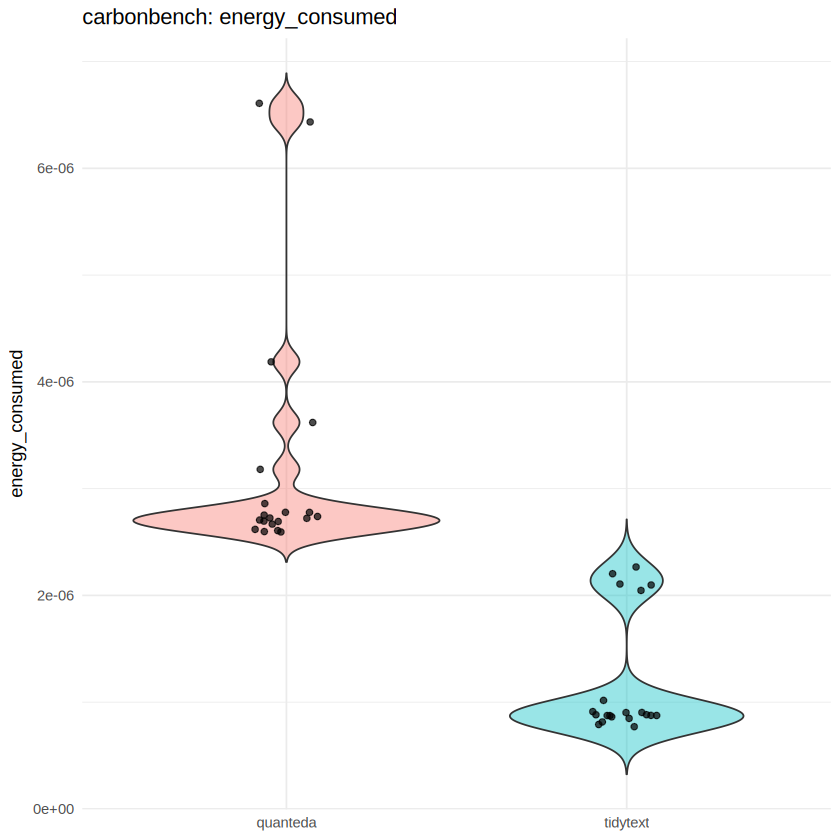

In [24]:
autoplot(bench, metric = "energy_consumed")

#### Latent semantic scaling

[LSX](https://koheiw.github.io/LSX/) implements latent semantic scaling
(LSS) (Watanabe, 2020), a semi-supervised approach. Instead of a fixed
dictionary, it starts from a small set of seed words and learns the
polarity of every other word from the texts themselves, by fitting a
model of how words co-occur. We compare it with the quanteda dictionary
approach, starting from the same texts:

In [25]:
sentiment_lss <- function(texts) {
  dfmt <- texts |>
    corpus(text_field = "text") |>
    corpus_reshape(to = "sentences") |>
    tokens(remove_punct = TRUE, remove_symbols = TRUE, remove_numbers = TRUE) |>
    dfm() |>
    dfm_remove(stopwords("en"))

  lss <- textmodel_lss(dfmt, seeds = as.seedwords(data_dictionary_sentiment), k = 300)

  tibble(id = seq_len(ndoc(dfmt)), score = predict(lss, newdata = dfmt)) |>
    mutate(sentiment = case_when(
      score > 0 ~ "positive",
      score < 0 ~ "negative",
      .default = "neutral"
    ))
}

bind_rows(
  quanteda = sentiment_quanteda(chapters),
  lss      = sentiment_lss(chapters),
  .id = "package"
) |>
  count(package, sentiment) |>
  pivot_wider(names_from = sentiment, values_from = n)

package,negative,neutral,positive
<chr>,<int>,<int>,<int>
lss,2967,31,2957
quanteda,1406,2549,2000


This isn’t a perfect comparison because LSS measures polarity
(positive - negative). However it is another approach to sentiment
analysis that adds a level of context missing in dictionary approaches.
More complex approaches require model training, using the results from
pre-trained models, or calls to external APIs.

In [26]:
bench_lss <- carbon_bench(
  quanteda = sentiment_quanteda(chapters),
  lss      = sentiment_lss(chapters),
  times = 20
)

bench_lss |>
  group_by(expr) |>
  summarise(
    duration_sec = median(duration),
    energy_wh    = median(energy_consumed) * 1000,
    co2e_mg      = median(emissions_total) * 1e6
  )

expr,duration_sec,energy_wh,co2e_mg
<chr>,<dbl>,<dbl>,<dbl>
lss,5.460399,0.019054972,4.8433238
quanteda,0.810802,0.002672041,0.6791698


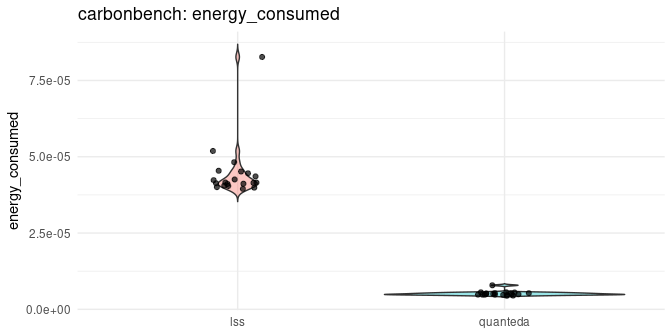

In [ ]:
autoplot(bench_lss, metric = "energy_consumed")

#### Tracking the Emissions of More Computationally Complex Methods

This tutorial is self-contained, in that it has avoided loading any
large models, model weights, or calls to external APIs. However, the
results demonstrated aren’t representative of the current
state-of-the-art in sentiment analysis. As the trend of the LSS
vs. Dictionary showed, as model complexity increases, so too does the
compute time, memory, and energy needs.

Of course, LLMs have much more
context, so their results are often an improvement over either of these
simpler approaches. We explored the tradeoff between Performance and
Energy Use across several classification tasks including sentiment
analysis, multi-class classification, and named entitity recognition
(Hamilton-Palicki et al., 2026). We found that even small reasoning LLMs
used up to 150,000 times more energy than Dictionaries for sentiment
analysis, while also doubling the performance.

We encourage researchers to provides these kinds of benchmarks across a
wider variety of tasks relevant to social scientists. The numbers
provided in this tutorial are purposefully small so as to provide an
introduction to tracking emissions using the TidyCarbon package, while
also not contributing unnecessarily to global greenhouse emissions
itself.

#### Sentiment Analysis with Large Language Models

In the code below I have included an example of estimating the emissions
of external API calls to Large Language Models for sentiment analysis. If you want to run this, you will need an openrouter account and it will cost you a few cents in LLM calls depending on the model you use.

The language model runs in a provider’s data center, reached through
[OpenRouter](https://openrouter.ai) with
[ellmer](https://ellmer.tidyverse.org) (Wickham et al., 2025). It needs
an API key. Put the key in a `.env` file, with no spaces around the `=`,
and keep that file out of version control:

    OPENROUTER_API_KEY=sk-or-...

The work happens in the provider’s data center, where the tracker from
`carbon_init()` cannot see it. `carbon_init_remote()` creates a tracker
for the provider instead: give it the chat, then pass it as `tracker`.
The estimate comes from [EcoLogits](https://ecologits.ai), which is
installed automatically through reticulate.

The code below is not run when the tutorial is rendered, because it
needs an API key and every request costs money. Check the price of the
model on OpenRouter before you run it.

Each impact column comes as a lower bound, a mean and an upper bound:
the provider does not publish the size of its models, so EcoLogits
brackets it. A remote tracker also estimates water, both what cools the
data center and what generating its electricity consumes. Check
`n_modelled` first: if it is 0, EcoLogits does not know the model and
the impact columns are `NA`.

Remote measurements are logged to their own file,
`emissions_remote.csv`, because their columns differ from a local
measurement.

In [27]:
install.packages("ellmer")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘coro’




In [37]:
# Replace 'sk-or-your-actual-key' with your real OpenRouter API key
# writeLines("OPENROUTER_API_KEY=YOURKEYHERE", ".env")

# Confirm that the file exists and is populated
# file.exists(".env")

[1] TRUE

In [38]:
library(ellmer)
readRenviron(".env")

chat <- chat_openrouter(
  model = "openai/gpt-6-luna",
  system_prompt = "You classify the sentiment of sentences from a novel.",
  echo = "none"
)

remote <- carbon_init_remote(
  chat,
  project_name = "Austen_tutorial",
  output_dir   = file.path(tempdir(), "tidycarbon_results")
)

# Number the sentences, so all of them go in a single prompt.
sentiment_type <- type_array(items = type_object(
  id        = type_integer("Number of the sentence"),
  sentiment = type_enum(values = c("positive", "neutral", "negative"))
))

classify <- function(sentences, chat) {
  prompt <- paste0(sentences$id, ". ", sentences$sentence, collapse = "\n")
  chat$chat_structured(prompt, type = sentiment_type)
}

# A random sample of 200 sentences keeps the request short and cheap.
set.seed(1234)
pride_sample <- slice_sample(pride, n = 10)

llm <- carbon_track(
  classify, pride_sample, chat,
  tracker = remote,
  label   = "LLM sentiment"
)

llm_labels <- llm$result[[1]]

llm |>
  transmute(
    label,
    wall_time_sec,
    n_modelled,
    output_tokens,
    energy_wh = energy_consumed_mean * 1000,
    co2e_mg   = emissions_total_mean * 1e6,
    water_ml  = water_consumed_mean * 1000
  )

Warning message:
“`Provider@model` was deprecated in ellmer 0.5.0.
ℹ Model details now live on the `Model` object; see `chat$get_model_object()`.
ℹ The deprecated feature was likely used in the tidycarbon package.
  Please report the issue at
  <https://github.com/seankellyhp/Tidycarbon/issues>.”


label,wall_time_sec,n_modelled,output_tokens,energy_wh,co2e_mg,water_ml
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
LLM sentiment,5.355418,1,254,0.03294194,13.84343,0.1187974


## Conclusion

Now you know how to track the time, energy, emissions and water use of R
code, from whole scripts to single pipeline steps and LLM API calls, and
how to compare the energy use of alternative methods.

## Technical Details

Visit the [GitHub repository](https://github.com/seankellyhp/Tidycarbon)
for the technical implementation.

## References

<span class="nocase">Balluff, P., Ho, J. C., Gruber, J. B., Palicki, S.,
Palmer, A., et al.</span> (2026). Newer, larger, better? A critique of
the unreflective LLM adoption in communication research. *Political
Communication*.

Benoit, K. (2025). *<span class="nocase">quanteda.sentiment</span>:
Sentiment analysis using <span class="nocase">quanteda</span>*.
<https://github.com/quanteda/quanteda.sentiment>

Benoit, K., Watanabe, K., Wang, H., Nulty, P., Obeng, A., Müller, S., &
Matsuo, A. (2018). <span class="nocase">quanteda</span>: An R package
for the quantitative analysis of textual data. *Journal of Open Source
Software*, *3*(30), 774. <https://doi.org/10.21105/joss.00774>

<span class="nocase">Courty, B., Schmidt, V., Goyal-Kamal, Coutarel, M.,
Blanche, L., Feld, B., et al.</span> (2026). *mlco2/codecarbon* (3.3.1).
Zenodo. <https://doi.org/10.5281/zenodo.4658424>

Hamilton-Palicki, S., & Bravo, I. (2026).
*<span class="nocase">tidycarbon</span>: Tidy R wrapper for
<span class="nocase">Python’s</span> CodeCarbon emissions tracker*.
<https://github.com/seankellyhp/Tidycarbon>

Hamilton-Palicki, S., Bravo, I., & Claessen, C. (2026). Don’t look up:
Evaluating the tradeoff between performance and sustainability of text
classification using open LLMs. *Social Science Computer Review*.
<https://doi.org/10.1177/08944393261473230>

Luccioni, A. S., Jernite, Y., & Strubell, E. (2024). Power hungry
processing: Watts driving the cost of AI deployment? *Proceedings of the
2024 ACM Conference on Fairness, Accountability, and Transparency*,
85–99. <https://doi.org/10.1145/3630106.3658542>

Rincé, S., & Banse, A. (2025). EcoLogits: Evaluating the environmental
impacts of generative AI. *Journal of Open Source Software*, *10*(111),
7471. <https://doi.org/10.21105/joss.07471>

Silge, J., & Robinson, D. (2017). *Text mining with R: A tidy approach*.
O’Reilly Media. <https://www.tidytextmining.com>

Watanabe, K. (2020). Latent semantic scaling: A semisupervised text
analysis technique for new domains and languages. *Communication Methods
and Measures*, *15*(2), 81–102.
<https://doi.org/10.1080/19312458.2020.1832976>

Wickham, H., Cheng, J., Jacobs, A., Aden-Buie, G., & Schloerke, B.
(2025). *Ellmer: Chat with large language models*.
<https://ellmer.tidyverse.org>

## Disclaimer

This method is intended for academic research; ensure legality and
ethics when processing chat data.